# ***Food Delivery Orders of ETA Logistics***

**Summary**:
*This project focuses on analyzing the food delivery orders dataset for ETA Logistics. It includes detailed information about orders, customers, restaurants, and drivers. The analysis aims to uncover insights regarding delivery times, peak hours, busiest days, customer types, and restaurant performance.*

Project Goal

This project teaches:
* **Exploratory Data Analysis (EDA)** with real-world food delivery data
* **Data cleaning and anomaly handling** (missing value imputation, duplicate verification, and zero-value treatment)
* **Data visualization** with matplotlib and seaborn
* **Market insight generation and strategic recommendation formulation**

In [2]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
#Import Dataset
Data=pd.read_excel("/content/food_delivery_orders_dataset.xlsx")

In [4]:
#Creating Dataframe
df = pd.DataFrame(Data)

In [5]:
#Check df heads
display(df.head())

,order_id,customer_id,restaurant_id,driver_id,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05,15,Sunday,1,City_C,City_C_Area_3,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01,20,Wednesday,0,City_A,City_A_Area_1,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07,18,Tuesday,0,City_C,City_C_Area_3,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30,16,Thursday,0,City_A,City_A_Area_1,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15,18,Wednesday,0,City_B,City_B_Area_6,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


In [6]:
#Check info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 36 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   order_id                             50000 non-null  object        
 1   customer_id                          50000 non-null  object        
 2   restaurant_id                        50000 non-null  object        
 3   driver_id                            50000 non-null  object        
 4   order_date                           50000 non-null  datetime64[ns]
 5   order_hour                           50000 non-null  int64         
 6   day_of_week                          50000 non-null  object        
 7   is_weekend                           50000 non-null  int64         
 8   city                                 50000 non-null  object        
 9   delivery_area                        50000 non-null  object        
 10  customer_a

In [7]:
#Check duplicate value
df.duplicated().sum()

np.int64(0)

No Duplicate value found on this dataset

In [8]:
#Check null values
df.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_id,0
driver_id,0
order_date,0
order_hour,0
day_of_week,0
is_weekend,0
city,0
delivery_area,0


#Removing null values
Filled Age and restaurant_rating column with used by mean function

Filled customer_type, restaurant_primary_category and restaurant_type column with used by mode function

In [9]:
df["customer_age"]=df["customer_age"].fillna(df["customer_age"].mean())

In [10]:
df["restaurant_rating"]=df["restaurant_rating"].fillna(df["restaurant_rating"].mean())

In [11]:
df["customer_type"]=df["customer_type"].fillna(df["customer_type"].mode()[0])

In [12]:
df["restaurant_type"]=df["restaurant_type"].fillna(df["restaurant_type"].mode()[0])

In [13]:
df["restaurant_primary_category"]=df["restaurant_primary_category"].fillna(df["restaurant_primary_category"].mode()[0])

In [14]:
#To drop orders which is cancelled orders
df=df[df["order_status"]!="Cancelled"]

**Dropped 868 rows, Which order was cancelled**

In [15]:
#Checking dataset after dropping 868 cancelled order rows
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49132 entries, 0 to 49999
Data columns (total 36 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   order_id                             49132 non-null  object        
 1   customer_id                          49132 non-null  object        
 2   restaurant_id                        49132 non-null  object        
 3   driver_id                            49132 non-null  object        
 4   order_date                           49132 non-null  datetime64[ns]
 5   order_hour                           49132 non-null  int64         
 6   day_of_week                          49132 non-null  object        
 7   is_weekend                           49132 non-null  int64         
 8   city                                 49132 non-null  object        
 9   delivery_area                        49132 non-null  object        
 10  customer_age   

#Checking datatype
Customer age column changed to "int" Data type which is currently in "float".

Other columns datatypes are accurate.

In [16]:

df["customer_age"]=df["customer_age"].astype(int)
df.dtypes


,0
order_id,object
customer_id,object
restaurant_id,object
driver_id,object
order_date,datetime64[ns]
order_hour,int64
day_of_week,object
is_weekend,int64
city,object
delivery_area,object


#Checking data consistency
Datas are consist

#Checking Outliers
The column "customer_age" was chosen for checking outliers

Total 13 data found but all are valid age

In [17]:

Q1=df["customer_age"].quantile(0.25)
Q3=df["customer_age"].quantile(0.75)
IQR=Q3-Q1
print(IQR)

12.0


In [18]:
lower_limit=Q1-1.5 * IQR
upper_limit=Q3+1.5 * IQR
print(lower_limit)
print(upper_limit)

3.0
51.0


In [19]:
df[(df["customer_age"]<lower_limit) | (df["customer_age"]>upper_limit)]

,order_id,customer_id,restaurant_id,driver_id,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
1636,ORD_001637,CUS_00308,RES_0034,DRV_0108,2025-10-19,12,Sunday,1,City_D,City_D_Area_8,...,High,2,4.8,10,21,27.0,1.0,Completed,NaN,3.7
9543,ORD_009544,CUS_01513,RES_0050,DRV_0182,2025-10-27,22,Monday,0,City_A,City_A_Area_9,...,High,39,4.3,10,31,50.0,1.0,Completed,NaN,3.4
13288,ORD_013289,CUS_05483,RES_0031,DRV_0049,2025-10-05,14,Sunday,1,City_B,City_B_Area_4,...,Low,5,4.3,6,24,26.0,0.0,Completed,NaN,4.8
14240,ORD_014241,CUS_03266,RES_0002,DRV_0037,2025-10-05,20,Sunday,1,City_D,City_D_Area_2,...,High,59,4.2,10,26,32.0,1.0,Completed,NaN,4.0
16338,ORD_016339,CUS_00308,RES_0002,DRV_0047,2025-10-06,12,Monday,0,City_D,City_D_Area_3,...,High,34,4.3,17,23,30.0,1.0,Completed,NaN,3.6
18762,ORD_018763,CUS_00308,RES_0012,DRV_0077,2025-10-14,12,Tuesday,0,City_D,City_D_Area_6,...,High,51,4.9,50,58,59.0,0.0,Completed,NaN,4.6
22821,ORD_022822,CUS_00308,RES_0002,DRV_0044,2025-10-01,7,Wednesday,0,City_D,City_D_Area_5,...,Medium,2,4.3,11,25,36.0,1.0,Completed,NaN,3.9
24550,ORD_024551,CUS_04429,RES_0208,DRV_0187,2025-10-18,20,Saturday,1,City_B,City_B_Area_8,...,Medium,4,4.2,19,40,41.0,0.0,Completed,NaN,4.9
27353,ORD_027354,CUS_00308,RES_0002,DRV_0159,2025-10-30,10,Thursday,0,City_D,City_D_Area_9,...,Medium,8,5.0,10,39,43.0,0.0,Completed,NaN,4.9
27829,ORD_027830,CUS_00308,RES_0012,DRV_0047,2025-10-29,13,Wednesday,0,City_D,City_D_Area_4,...,High,34,4.3,17,44,45.0,0.0,Completed,NaN,4.4


#**Exploratory Data Analysis**

In [20]:
#Picking Numerical Columns
Colomns=["order_hour",
         "customer_age",
         "items_count",
         "subtotal",
         "tax_amount",
         "service_fee",
         "delivery_fee",
         "order_total",
         "distance_km",
         "actual_delivery_time_minutes",
         "customer_rating"]

In [21]:
#Mean
df[Colomns].mean()

,0
order_hour,14.460779
customer_age,27.695392
items_count,2.908430
subtotal,30.874788
tax_amount,4.125827
service_fee,1.473473
delivery_fee,3.076647
order_total,38.145741
distance_km,4.728153
actual_delivery_time_minutes,35.152365


In [22]:
#Median
df[Colomns].median()

,0
order_hour,14.00
customer_age,27.00
items_count,2.00
subtotal,22.80
tax_amount,2.89
service_fee,1.04
delivery_fee,3.50
order_total,28.36
distance_km,4.10
actual_delivery_time_minutes,33.00


In [23]:
#Mode
df[Colomns].mode()

,order_hour,customer_age,items_count,subtotal,tax_amount,service_fee,delivery_fee,order_total,distance_km,actual_delivery_time_minutes,customer_rating
0,19.0,18.0,1.0,10.16,1.08,0.56,0.0,14.33,3.0,29.0,5.0
1,NaN,NaN,NaN,NaN,1.09,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,1.23,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
#Average delivery time by restaurant
df.groupby("restaurant_type")["actual_delivery_time_minutes"].mean()


,actual_delivery_time_minutes
restaurant_type,
Cafe,31.290786
Casual Dining,38.599751
Fast Food,34.111332
Fine Dining,47.733447


*   Fast food delivery is faster when comparing other restaurant type
*   Fine Dining taking more time for delivery



In [25]:
#Total delivery count by restaurant category
df.groupby("restaurant_primary_category")["items_count"].size()

,items_count
restaurant_primary_category,
Asian,3743
Burger,15910
Dessert,9418
Healthy,3541
Local,12495
Pizza,4025


This statistics showing more customers liked to order **Burger**

#**Data visualization**

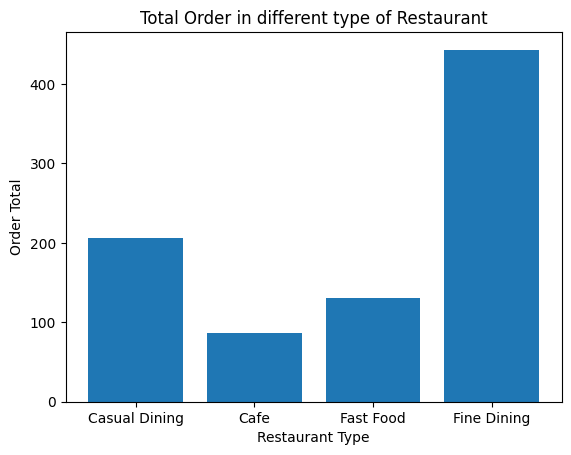

In [26]:
#Bar plot: restaurant_type by order_total
plt.bar(df["restaurant_type"],df["order_total"])
plt.xlabel("Restaurant Type")
plt.ylabel("Order Total")
plt.title("Total Order in different type of Restaurant")
plt.show()




*  Fine Dining has the highest order
*  Cafe has the lowest order



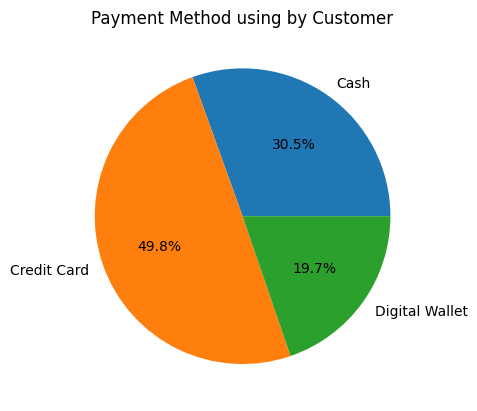

In [27]:
#Pie Chart for showing payment method for Order
plt.pie(df.groupby("payment_method")["order_total"].sum(),labels=df.groupby("payment_method")["order_total"].sum().index,autopct="%1.1f%%")
plt.title("Payment Method using by Customer")
plt.show()

**Most customers are likely to order food by using Credit Card**

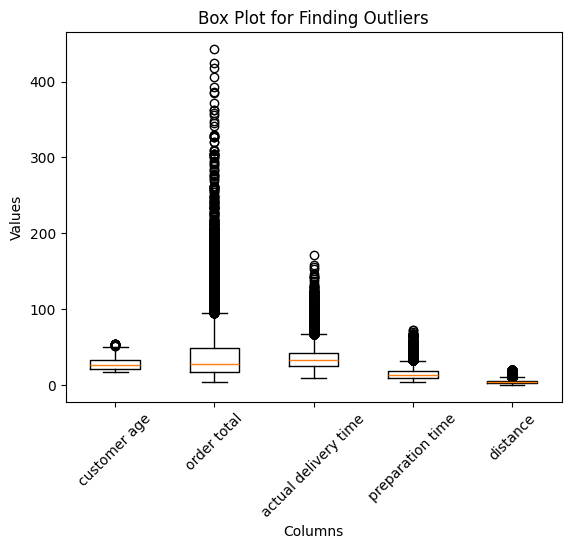

In [28]:
#Box Plot : To check outliers in Age column
plt.boxplot([df["customer_age"],df["order_total"],df["actual_delivery_time_minutes"],df["restaurant_preparation_time_minutes"],df["distance_km"]],tick_labels=["customer age","order total","actual delivery time","preparation time","distance"])
plt.xlabel("Columns")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.title("Box Plot for Finding Outliers")
plt.show()

**The box plot reveals numerous outliers for order totals, with many orders significantly above the median, indicating the presence of exceptionally large orders in the dataset.**

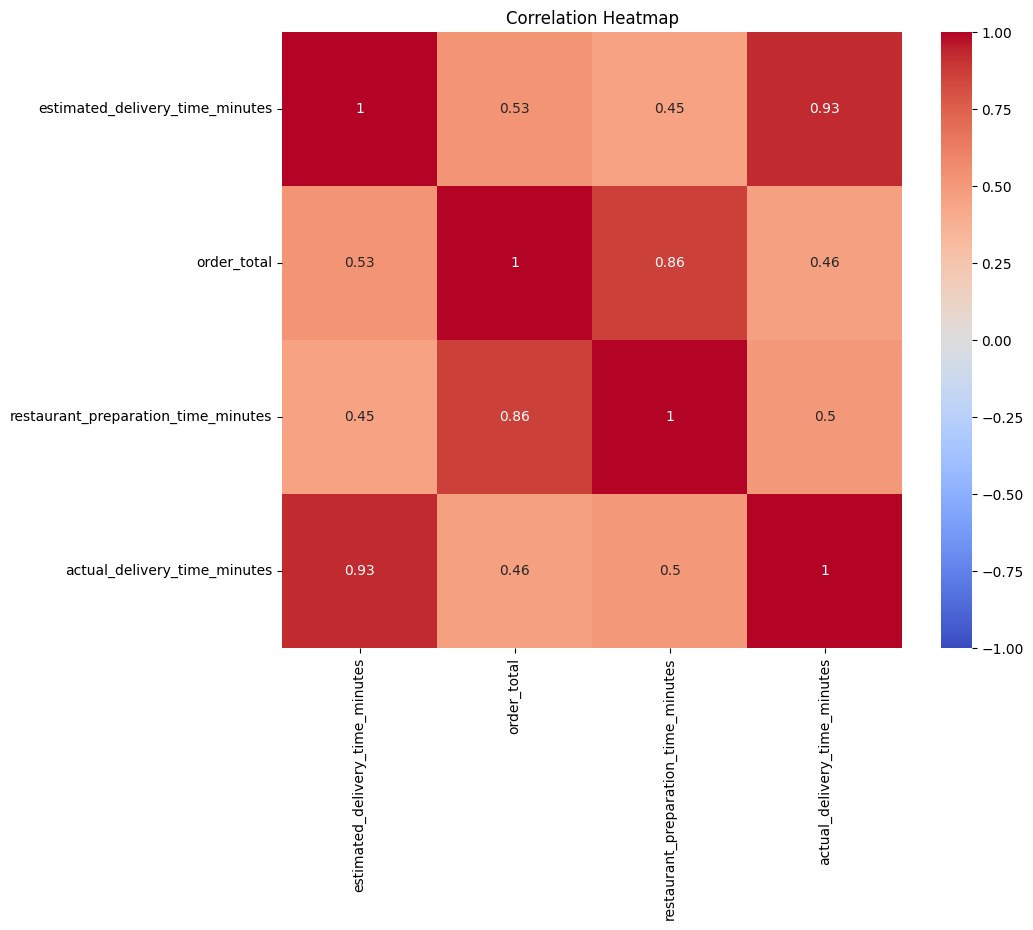

In [29]:
#Heatmap: correlation matrix
selected_cols = [
    "estimated_delivery_time_minutes",
    "order_total",
    "restaurant_preparation_time_minutes",
    "actual_delivery_time_minutes",
]
corr_matrix = df[selected_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

**The Heatmap shows a strong positive correlation between restaurant preparation time and order total and it meaning that larger orders take longer to prepare.**

**There is also a positive correlation between estimated_delivery_time_minutes and actual delivery time, This correlation meaning orders are delivered on time.**

In [35]:
fig = px.violin(
    df,
    x="restaurant_type",
    y="restaurant_rating",
    box=True,
    points="all",
    title="Rating Distribution by Restaurant Type",
)
fig.show()

**Casual and Fine Dining categories show a heavy concentration of ratings toward the higher End of the Scale, approximately 4 to 5. This indicates positive customer feedback**

**The Cafe category also maintains a high rating; its median rating is 4.5, which is very good.**

**The fast food category has a much wider distribution and greater variability in rating. Also its median rating is below 4.0.**


In [31]:
#Line Chart : To show hourly order Trend
hourly_orders = (
    df.groupby("order_hour").size().reset_index(name="order_count")
)
fig1 = px.line(
    hourly_orders,
    x="order_hour",
    y="order_count",
    title="Hourly Order Trends",
    labels={"order_hour": "Hour of Day", "order_count": "Number of Orders"},
    markers=True,
)
fig1.show()

**This graph shows the distribution of hourly orders. Orders start increasing around 5 AM and the peak time is around 11 AM; then orders go higher again, peaking around 7 PM**

In [32]:
pd.set_option("display.max_columns",None)
display(df.head())

,order_id,customer_id,restaurant_id,driver_id,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,payment_method,tip_amount,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05,15,Sunday,1,City_C,City_C_Area_3,40,Premium,Casual Dining,Healthy,4.400000,4,64.82,0,9.07,2.40,0.00,76.29,Credit Card,11.36,1.1,Rain,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01,20,Wednesday,0,City_A,City_A_Area_1,19,Regular,Cafe,Dessert,4.400000,2,13.03,0,1.82,0.84,3.25,18.94,Cash,1.09,2.5,Cloudy,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07,18,Tuesday,0,City_C,City_C_Area_3,26,Regular,Fast Food,Dessert,4.800000,1,10.12,10,1.28,0.56,7.90,18.85,Cash,0.00,11.8,Cloudy,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30,16,Thursday,0,City_A,City_A_Area_1,18,New,Fast Food,Local,4.207937,1,8.86,10,1.12,0.40,4.70,14.19,Digital Wallet,0.00,5.4,Cloudy,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15,18,Wednesday,0,City_B,City_B_Area_6,20,Regular,Casual Dining,Burger,3.500000,1,15.08,20,1.69,0.65,5.05,19.45,Credit Card,1.70,6.1,Rain,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9
